<a href="https://colab.research.google.com/github/cozen03/2026-Programming/blob/main/%EC%A0%84%EB%B3%B5_%EB%82%98%EC%9D%B4_%EC%98%88%EC%B8%A1_%EB%AA%A8%EB%8D%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv('abalone.csv')
df.head()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4178 entries, 0 to 4177
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             4178 non-null   int64  
 1   sex            4177 non-null   object 
 2   length         4177 non-null   float64
 3   diameter       4177 non-null   float64
 4   height         4177 non-null   float64
 5   whole_wight    4177 non-null   float64
 6   shucked_width  4177 non-null   float64
 7   viscera_width  4177 non-null   float64
 8   shell_width    4177 non-null   float64
 9   class_rings    4177 non-null   float64
dtypes: float64(8), int64(1), object(1)
memory usage: 326.5+ KB


In [ ]:
df.describe()

,id,length,diameter,height,whole_wight,shucked_width,viscera_width,shell_width,class_rings
count,4178.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,2089.500000,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,1206.229041,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,1.000000,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,1045.250000,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,2089.500000,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,3133.750000,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,4178.000000,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [ ]:
from matplotlib import pyplot as plt

# 문자열 열(Sex)을 제외하고 박스플롯 그리기
plt.boxplot(df.drop('id', axis=1))
plt.show()

plt.boxplot(df)
plt.show()

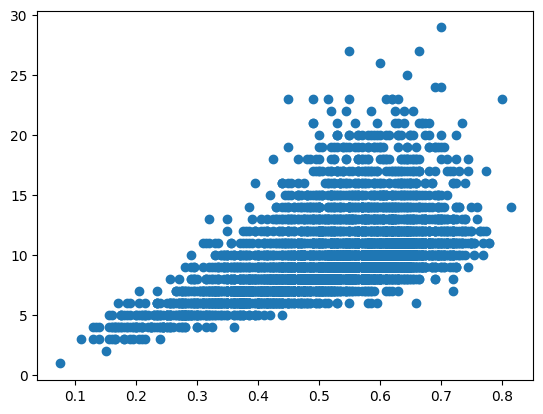

In [ ]:
plt.scatter(df['length'], df['class_rings'])
plt.show()

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# 결측치가 있는 행 제거 추가
df = df.dropna()

X = df['length'].values.reshape(-1,1)
y = df['class_rings'].values

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
X_train

array([[0.35 ],
       [0.625],
       [0.5  ],
       ...,
       [0.715],
       [0.37 ],
       [0.715]])

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
print(model.coef_, model.intercept_)

[14.92856953] 2.1466243290838563


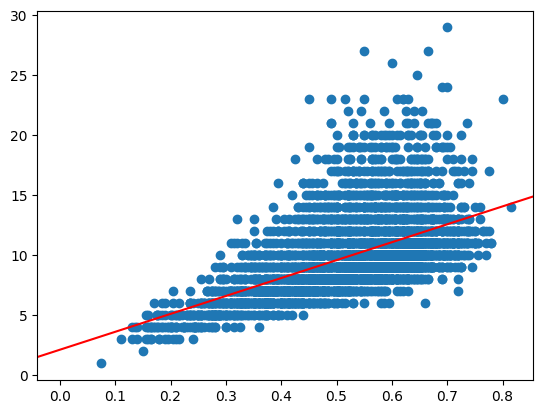

In [ ]:
slope = model.coef_[0]
intercept = model.intercept_

plt.axline((0,intercept), slope=slope, color='red')

plt.scatter(df['length'], df['class_rings'])
plt.show()

In [ ]:
print(model.score(X_train, y_train))

0.3096376452595315


In [ ]:
print(model.score(X_test, y_test))

0.3096410686625133


In [ ]:
predictions = model.predict(X_test)

print(f"예측값: {predictions[:5]}")
print(f"실제값: {y_test[:5]}")

예측값: [10.43198042 11.55162313 11.25305174 11.55162313 10.05876618]
실제값: [ 8.  8. 11. 10. 14.]


In [ ]:
X_mul = df.iloc[:,2:-1].values
y = df['class_rings'].values
X_mul.shape

(4177, 7)

In [ ]:
X_mul_train, X_mul_test, y_train, y_test = train_test_split(X_mul, y, test_size=0.3)
X_mul_train

array([[0.535 , 0.39  , 0.125 , ..., 0.2595, 0.149 , 0.169 ],
       [0.55  , 0.45  , 0.175 , ..., 0.3765, 0.215 , 0.4   ],
       [0.61  , 0.495 , 0.165 , ..., 0.4525, 0.273 , 0.317 ],
       ...,
       [0.415 , 0.33  , 0.1   , ..., 0.1925, 0.0755, 0.1025],
       [0.645 , 0.52  , 0.175 , ..., 0.779 , 0.342 , 0.432 ],
       [0.555 , 0.44  , 0.15  , ..., 0.416 , 0.212 , 0.4405]])

In [ ]:
model_mul = LinearRegression()
model_mul.fit(X_mul_train, y_train)

LinearRegression()

In [ ]:
print(model_mul.score(X_mul_train, y_train))
print(model_mul.score(X_mul_test, y_test))

0.543468492287688
0.47761997389105704
